# 03 - Modelling and Comparison

**Coursework Part 01, Task 2.II**

**Goal:** train, tune and compare three classifiers — **K-Nearest Neighbours (KNN)**, **Logistic Regression** and **Random Forest** — for predicting customer churn, and identify the most suitable model.

**Input:** `data/train.csv` and `data/test.csv` from `02_preprocessing.ipynb` (cleaned, unencoded, `Churn` = 1/0).

This notebook defines the experiments (models, hyperparameter grids, settings) and interprets the results.

## Setup

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (classification_report, precision_recall_curve,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from src.cm2604_ml_cw.preprocessing import encode
from src.cm2604_ml_cw.evaluation import *

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

TRAIN_PATH = Path("../data/processed/train.csv")
TEST_PATH = Path("../data/processed/test.csv")

RANDOM_STATE = 20080337
SAVE_FIGS = True            # set to False if you don't want PNGs in figures/

## Load The Data

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns="Churn"), train["Churn"]
X_test, y_test = test.drop(columns="Churn"), test["Churn"]

pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
    "churn_rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"]).style.format({"churn_rate": "{:.2%}"})

,rows,features,churn_rate
train,5634,19,26.54%
test,1409,19,26.54%


## Encoding And Scaling

In [3]:
# KNN and Logistic Regression: encoding + scaling
X_train_scaled, X_test_scaled, preprocessor_scaled = encode(X_train, X_test, scale=True)

Scaling applied         : True
Features before encoding: 19
Features after encoding : 40

['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Cre

In [4]:
# Random Forest: encoding only
X_train_rf, X_test_rf, preprocessor_rf = encode(X_train, X_test, scale=False, verbose=False)
print("Random Forest features:", X_train_rf.shape[1])
X_train_rf[["tenure", "MonthlyCharges", "TotalCharges"]].head(3)

Random Forest features: 40


,tenure,MonthlyCharges,TotalCharges
0,20,20.35,393.15
1,72,97.25,7133.10
2,23,84.40,1936.85


## Evaluation Strategy

- **Primary metric: F1-score for the churn class.** The data is imbalanced (26.5% churn), so accuracy is misleading: predicting "no churn" for everyone already gives ~73%. F1 balances **precision** and **recall**.
- **Also reported:** recall, precision, ROC-AUC and PR-AUC.
- **Tuning:** stratified 5-fold cross-validation on the **training set only**, so every fold keeps the 26.5% churn rate. The test set is used once, at the end.
- **Class imbalance:** handled with `class_weight="balanced"` for Logistic Regression and Random Forest. Mistakes on churners are weighted more heavily, in proportion to how rare they are. KNN has no class-weight option, so its imbalance is handled through the choice of metric.

The helper functions (`results_table`, `best_scores`, `plot_validation_curve`, `evaluate`, `save_fig`) are in `src/cm2604_ml_cw/evaluation.py`.

In [5]:
# Stratified 5-fold CV used for every model
cv = make_cv(RANDOM_STATE)

# Metrics recorded during cross-validation (defined in src/evaluation.py)
list(SCORING)

['f1', 'recall', 'precision', 'roc_auc']

## Baseline And Default Models

Before tuning, each model is evaluated with its default hyperparameters, alongside a **majority-class baseline** that always predicts "no churn". This gives a reference point for measuring the effect of tuning.

In [6]:
default_models = {
    "Baseline (majority class)": (DummyClassifier(strategy="most_frequent"), X_train_scaled),
    "KNN": (KNeighborsClassifier(), X_train_scaled),
    "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), X_train_scaled),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), X_train_rf),
}

rows = {}
for name, (model, X) in default_models.items():
    scores = cross_validate(model, X, y_train, cv=cv, n_jobs=-1,
                            scoring={"accuracy": "accuracy", **SCORING})
    rows[name] = {
        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
        "f1_std": scores["test_f1"].std(),
        "roc_auc": scores["test_roc_auc"].mean(),
    }

default_cv = pd.DataFrame(rows).T.round(4)
default_cv

,accuracy,precision,recall,f1,f1_std,roc_auc
Baseline (majority class),0.7346,0.0000,0.0000,0.0000,0.0000,0.5000
KNN,0.7675,0.5673,0.5264,0.5457,0.0126,0.7790
Logistic Regression,0.8040,0.6564,0.5505,0.5986,0.0138,0.8422
Random Forest,0.7891,0.6353,0.4816,0.5476,0.0209,0.8180


**Observations**
- The baseline reaches **73.5% accuracy with 0 recall and 0 F1**: it never identifies a single churner. This confirms that accuracy is not a suitable metric for this problem.
- All three default models beat the baseline, but **none handles the imbalance**. Their recall is only 0.50-0.55, so they miss about half of the churners. With 73% of customers staying, the default 0.5 threshold pushes them towards predicting "no churn".
- **Logistic Regression** is the strongest default model (CV F1 0.595, ROC-AUC 0.844).
- The default **Random Forest** has high accuracy (0.791) but the lowest recall (0.500).
- The default **KNN** (k = 5) has the lowest ROC-AUC (0.780). A small k makes it sensitive to noise in individual customers.

## Hyperparameter Tuning

Each model is tuned with `GridSearchCV`, choosing the combination with the best **CV F1**. Recall, precision and ROC-AUC are recorded too, and training scores are kept to check for overfitting.

### K-Nearest Neighbours

| Hyperparameter | Meaning | Values |
|---|---|---|
| `n_neighbors` (k) | number of neighbours that vote | 3 - 81 |
| `weights` | `uniform`: equal votes; `distance`: closer neighbours count more | both |
| `metric` | distance measure | Euclidean, Manhattan |

Small k gives a very flexible model with high variance (overfitting). Large k gives a smoother boundary with higher bias. Odd values avoid tied votes.

In [7]:
knn_grid = {
    "n_neighbors": [3, 5, 11, 21, 31, 51, 71, 81],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}

knn_search = GridSearchCV(KNeighborsClassifier(), knn_grid, scoring=SCORING, refit="f1",
                          cv=cv, n_jobs=-1, return_train_score=True)
knn_search.fit(X_train_scaled, y_train)

print("Best parameters:", knn_search.best_params_)
print(f"Best CV F1: {knn_search.best_score_:.4f}")
results_table(knn_search, top=8)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 71, 'weights': 'uniform'}
Best CV F1: 0.6000


,metric,n_neighbors,weights,train_f1,cv_f1,cv_f1_std,train_cv_gap,cv_recall,cv_precision,cv_roc_auc,rank
0,manhattan,71,uniform,0.6095,0.6000,0.0183,0.0094,0.5779,0.6257,0.8344,1
1,manhattan,81,uniform,0.6089,0.5998,0.0165,0.0092,0.5786,0.6242,0.8343,2
2,euclidean,51,uniform,0.6049,0.5979,0.0149,0.0069,0.5739,0.6259,0.8318,3
3,manhattan,51,uniform,0.6059,0.5958,0.0136,0.0101,0.5732,0.6223,0.8321,4
4,euclidean,81,uniform,0.6051,0.5946,0.0106,0.0105,0.5692,0.6243,0.8339,5
5,euclidean,71,uniform,0.6053,0.5928,0.0148,0.0126,0.5645,0.6258,0.8338,6
6,manhattan,71,distance,0.9977,0.5916,0.0153,0.4061,0.5692,0.6168,0.8267,7
7,manhattan,81,distance,0.9977,0.5906,0.0135,0.4071,0.5686,0.6158,0.8270,8


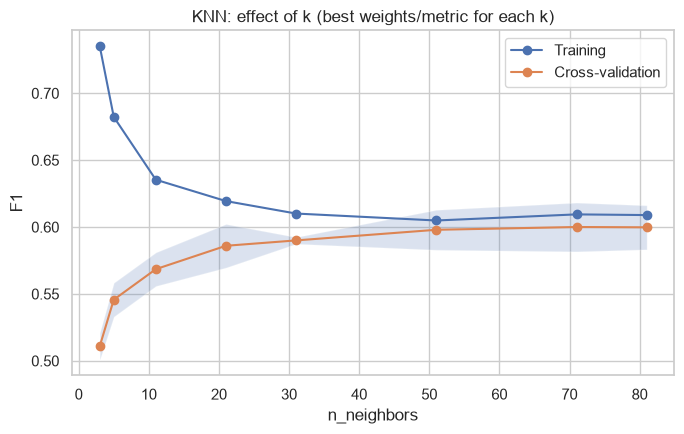

In [8]:
plot_validation_curve(knn_search, "n_neighbors", title="KNN: effect of k (best weights/metric for each k)")
save_fig("M01_knn_validation_k", SAVE_FIGS)
plt.show()

**Observations**
- Best setting: **k = 71, uniform weights, Manhattan distance** (CV F1 0.6000).
- The best k is a **larger value in the grid**, so an even larger k might score slightly higher. The gains are levelling off, though (+0.006 F1 from k = 51 to k = 81).
- **`weights="distance"` overfits badly.** Each training customer is its own nearest neighbour at distance 0, so training F1 is ~0.996 for every k, while CV F1 is *lower* than with uniform weights at every k.
- Euclidean and Manhattan distance perform almost identically (CV F1 0.6000 vs 0.5979).
- KNN has no class-weight option, so its CV recall stays low (0.59): it still misses about 40% of churners.

### Logistic Regression

| Hyperparameter | Meaning | Values |
|---|---|---|
| `C` | inverse regularisation strength: small C = strong regularisation (simpler model) | 0.001 - 100 |
| `l1_ratio` | 0 = L2 (ridge, shrinks all coefficients), 1 = L1 (lasso, can set coefficients to exactly 0) | 0, 1 |
| `class_weight` | `None`: every customer counts equally; `"balanced"`: churners weighted ~2.8× more | both |

`liblinear` supports both L1 and L2.

In [9]:
lr_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0, 1],
    "class_weight": [None, "balanced"],
    "solver": ["liblinear"],
}

lr_search = GridSearchCV(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), lr_grid,
                         scoring=SCORING, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
lr_search.fit(X_train_scaled, y_train)

print("Best parameters:", lr_search.best_params_)
print(f"Best CV F1: {lr_search.best_score_:.4f}")
results_table(lr_search, top=8)

Best parameters: {'C': 10, 'class_weight': 'balanced', 'l1_ratio': 0, 'solver': 'liblinear'}
Best CV F1: 0.6281


,C,class_weight,l1_ratio,solver,train_f1,cv_f1,cv_f1_std,train_cv_gap,cv_recall,cv_precision,cv_roc_auc,rank
0,10.0,balanced,0,liblinear,0.6295,0.6281,0.0140,0.0014,0.8054,0.5150,0.8420,1
1,10.0,balanced,1,liblinear,0.6298,0.6274,0.0126,0.0024,0.8040,0.5146,0.8420,2
2,100.0,balanced,1,liblinear,0.6296,0.6272,0.0137,0.0024,0.8047,0.5141,0.8420,3
3,100.0,balanced,0,liblinear,0.6296,0.6272,0.0137,0.0023,0.8047,0.5141,0.8420,3
4,1.0,balanced,1,liblinear,0.6286,0.6272,0.0140,0.0015,0.8020,0.5151,0.8420,5
5,1.0,balanced,0,liblinear,0.6289,0.6270,0.0131,0.0019,0.8020,0.5149,0.8420,6
6,0.1,balanced,0,liblinear,0.6285,0.6263,0.0145,0.0021,0.7973,0.5159,0.8416,7
7,0.1,balanced,1,liblinear,0.6274,0.6250,0.0152,0.0024,0.7980,0.5139,0.8414,8


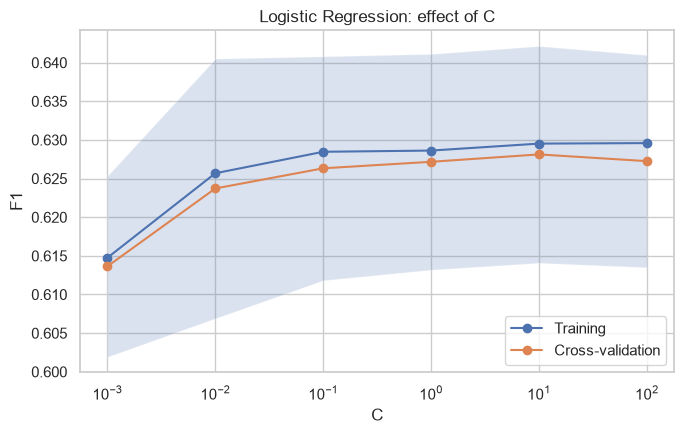

In [10]:
plot_validation_curve(lr_search, "C", log_x=True, title="Logistic Regression: effect of C")
save_fig("M02_lr_validation_C", SAVE_FIGS)
plt.show()

**Observations**
- Best setting: **C = 10, L2 regularisation (`l1_ratio = 0`), `class_weight="balanced"`** (CV F1 0.6281). L1 at C = 10 scores practically the same (0.6274 vs 0.6281).
- **Performance is almost flat for C between 0.1 and 100** (CV F1 0.625 - 0.628). The whole spread (0.003) is smaller than one CV standard deviation (about 0.013 - 0.015), so the differences between the top 8 combinations aren't meaningful. Any of them would do.
- **There's no sign of overfitting.** The train/CV gap stays below 0.003 for every combination. With 40 features and 5,600 training rows, Logistic Regression is a low-variance model and doesn't overfit this data.
- **The model favours recall over precision.** CV recall is about 0.80 and precision about 0.515, so it finds around 80% of churners, but roughly half of its churn predictions are false alarms. This is the expected effect of `class_weight="balanced"` on an imbalanced target.
- **Ranking ability is stable.** CV ROC-AUC is 0.841–0.842 for every combination, so the choice of C and penalty barely changes how well the model separates churners from non-churners.

### Random Forest

| Hyperparameter | Meaning | Values |
|---|---|---|
| `n_estimators` | number of trees | 200, 300 |
| `max_depth` | maximum depth of each tree (`None` = grow fully) | None, 6, 10, 14 |
| `min_samples_leaf` | minimum customers in a leaf; larger = smoother, less overfitting | 1, 5, 10, 20 |
| `max_features` | features considered at each split; adds randomness between trees | sqrt, log2, 0.5 |
| `class_weight` | `None` or `"balanced"` | both |

The full grid has 192 combinations.

In [11]:
rf_grid = {
    "n_estimators": [200, 300],
    "max_depth": [None, 6, 10, 14],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced"],
}

rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_grid,
                         scoring=SCORING, refit="f1", cv=cv, n_jobs=-1,
                         return_train_score=True)
rf_search.fit(X_train_rf, y_train)

print("Best parameters:", rf_search.best_params_)
print(f"Best CV F1: {rf_search.best_score_:.4f}")
results_table(rf_search, top=8)

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 20, 'n_estimators': 200}
Best CV F1: 0.6317


,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,train_f1,cv_f1,cv_f1_std,train_cv_gap,cv_recall,cv_precision,cv_roc_auc,rank
0,balanced,None,log2,20,200,0.6593,0.6317,0.0151,0.0276,0.7853,0.5287,0.8445,1
1,balanced,None,sqrt,20,200,0.6632,0.6312,0.0141,0.0320,0.7799,0.5302,0.8444,2
2,balanced,14,sqrt,20,200,0.6633,0.6311,0.0147,0.0321,0.7793,0.5305,0.8444,3
3,balanced,10,log2,10,200,0.6838,0.6310,0.0098,0.0528,0.7786,0.5306,0.8439,4
4,balanced,10,sqrt,20,300,0.6635,0.6310,0.0143,0.0325,0.7839,0.5282,0.8447,5
5,balanced,14,sqrt,20,300,0.6629,0.6307,0.0148,0.0322,0.7813,0.5289,0.8445,6
6,balanced,None,sqrt,20,300,0.6629,0.6307,0.0153,0.0322,0.7813,0.5289,0.8445,7
7,balanced,10,log2,10,300,0.6850,0.6303,0.0095,0.0546,0.7773,0.5302,0.8441,8


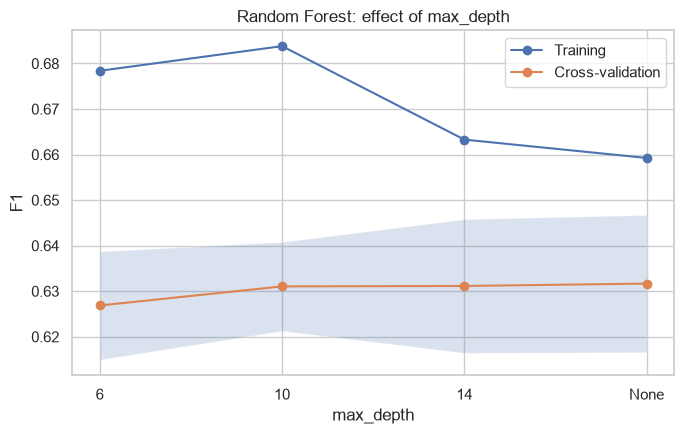

In [12]:
plot_validation_curve(rf_search, "max_depth", title="Random Forest: effect of max_depth")
save_fig("M03_rf_validation_depth", SAVE_FIGS)
plt.show()

**Observations**
- **Best setting:** 200 trees, no depth limit, `min_samples_leaf = 20`, `max_features = "log2"`, `class_weight = "balanced"`. It reached **CV F1 = 0.632** (± 0.015), with ROC-AUC 0.845, recall 0.785 and precision 0.529.
- **Leaf size controls overfitting, not depth.** `max_depth` is unlimited, but `min_samples_leaf = 20` stops the trees from memorising individual customers. The gap between training and CV F1 is only 0.028.
- **Depth makes almost no difference.** Depths of `None`, 14 and 10 all appear in the top 8 with nearly identical scores. For example, rank 2 (no limit) and rank 3 (depth 14) differ by only 0.0001. With leaves of at least 20 samples, the trees probably rarely reach the depth limit.
- **Smaller leaves overfit more without improving CV.** With `min_samples_leaf = 10` (ranks 4 and 8), training F1 rises to about 0.684 and the gap roughly doubles to about 0.053. CV F1 stays the same, so larger leaves are the better choice.
- **The top results are practically tied.** The top 8 span only 0.0014 in CV F1 (0.6303 - 0.6317), well within the fold-to-fold standard deviation (about 0.010 - 0.015). The model is not sensitive to these settings once leaf size is large enough.
- **More trees don't help.** 200 and 300 trees give the same CV F1, so 200 is the cheaper choice.

### Effect Of Tuning

In [13]:
searches = {"KNN": knn_search, "Logistic Regression": lr_search, "Random Forest": rf_search}

tuning_effect = pd.DataFrame({
    name: {"default_cv_f1": default_cv.loc[name, "f1"], "tuned_cv_f1": s.best_score_}
    for name, s in searches.items()
}).T
tuning_effect["improvement"] = tuning_effect["tuned_cv_f1"] - tuning_effect["default_cv_f1"]
tuning_effect.round(4)

,default_cv_f1,tuned_cv_f1,improvement
KNN,0.5457,0.6000,0.0543
Logistic Regression,0.5986,0.6281,0.0295
Random Forest,0.5476,0.6317,0.0841


**Observations**
- Tuning improved every model: **Random Forest +0.0841 F1, KNN +0.0543, Logistic Regression +0.0295**.
- For Logistic Regression and Random Forest, much of the gain comes from `class_weight="balanced"`. For KNN, it comes from using a much larger k.

## Experimental Setting: Class Weighting VS No Class Weighting

`class_weight` was included in the Logistic Regression and Random Forest searches, so the two settings can be compared directly. The comparison below takes the **best combination with `class_weight=None`** and the **best with `class_weight="balanced"`**. All scores are CV means on the training set.

In [14]:
rows = []
for name in ["Logistic Regression", "Random Forest"]:
    for setting in ["None", "balanced"]:
        scores = best_scores(searches[name], mask=lambda r, v=setting: r["param_class_weight"].map(param_label) == v)
        rows.append({"model": name, "class_weight": setting, **scores})

weight_comparison = pd.DataFrame(rows).set_index(["model", "class_weight"]).round(4)
weight_comparison

f1  recall  precision  roc_auc
model               class_weight                                    
Logistic Regression None          0.5973  0.5485     0.6562   0.8421
                    balanced      0.6281  0.8054     0.5150   0.8420
Random Forest       None          0.5735  0.5043     0.6654   0.8414
                    balanced      0.6317  0.7853     0.5287   0.8445

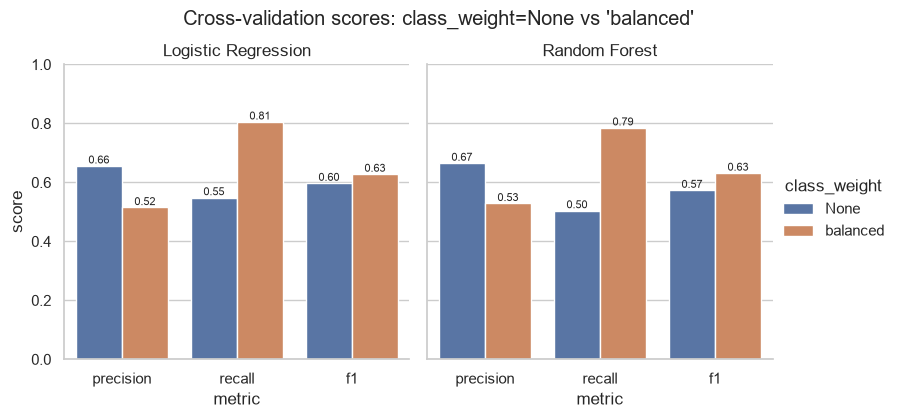

In [15]:
plot_df = weight_comparison.reset_index().melt(id_vars=["model", "class_weight"],
                                               value_vars=["precision", "recall", "f1"],
                                               var_name="metric", value_name="score")
g = sns.catplot(data=plot_df, x="metric", y="score", hue="class_weight", col="model",
                kind="bar", height=4, aspect=1, palette=["#4C72B0", "#DD8452"])
g.set_titles("{col_name}")
g.set(ylim=(0, 1))
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8)
g.fig.suptitle("Cross-validation scores: class_weight=None vs 'balanced'", y=1.04)
save_fig("M04_class_weight_comparison", SAVE_FIGS)
plt.show()

**Observations**
- `class_weight="balanced"` increased F1 for both models: **Logistic Regression +0.031** (0.597 -> 0.628) and **Random Forest +0.058** (0.574 -> 0.632).
- It does this by **trading precision for recall**. Recall rises by 0.26 (LR) and 0.28 (RF), while precision falls by 0.14 for both models.
- **ROC-AUC is almost unchanged** (LR 0.842 in both settings; RF 0.841 -> 0.845). Class weighting does not make the models better at *ranking* customers by risk. It mainly moves the decision boundary so that churn is predicted more often.
- With balanced weights, **Random Forest and Logistic Regression are practically tied** (CV F1 0.632 vs 0.628). The 0.004 gap is smaller than the fold-to-fold variation (about 0.015), so the Random Forest's lead is not clearly meaningful.
- For churn prediction, catching more churners is usually worth some extra false alarms, so the balanced setting is preferred. The choice was made on CV F1, not on the test set.

## Final Comparison On The Test Set

The tuned models are now evaluated **once** on the 1,409 held-out test customers, which were not used for training or tuning. Each model gets the version of the test set that matches its training data: scaled for KNN and Logistic Regression, unscaled for Random Forest.

In [16]:
final_models = {
    "KNN": (knn_search.best_estimator_, X_test_scaled),
    "Logistic Regression": (lr_search.best_estimator_, X_test_scaled),
    "Random Forest": (rf_search.best_estimator_, X_test_rf),
}

baseline = DummyClassifier(strategy="most_frequent").fit(X_train_scaled, y_train)

test_results = pd.DataFrame({
    **{name: evaluate(model, X, y_test) for name, (model, X) in final_models.items()},
    "Baseline (majority class)": evaluate(baseline, X_test_scaled, y_test),
}).T.sort_values("f1", ascending=False).round(4)
test_results

,accuracy,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.7722,0.5484,0.8021,0.6515,0.8576,0.6688
Logistic Regression,0.7551,0.5251,0.8102,0.6372,0.8562,0.6650
KNN,0.8013,0.6298,0.6096,0.6196,0.8503,0.6406
Baseline (majority class),0.7346,0.0000,0.0000,0.0000,0.5000,0.2654


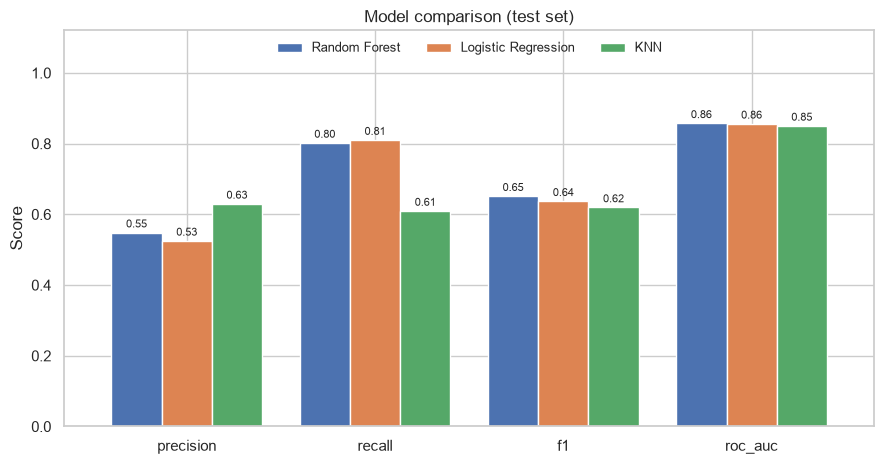

In [17]:
plot_data = test_results.drop(index="Baseline (majority class)")[["precision", "recall", "f1", "roc_auc"]]

ax = plot_data.T.plot(kind="bar", figsize=(9, 4.8), width=0.8, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Model comparison (test set)")
ax.legend(loc="upper center", ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
save_fig("M05_test_metric_comparison", SAVE_FIGS)
plt.show()

In [18]:
for name, (model, X) in final_models.items():
    print(name.center(54))
    print("------------------------------------------------------")
    print(classification_report(y_test, model.predict(X), digits=3,
                                target_names=["Stayed (0)", "Churned (1)"]))
    print("\n")

                         KNN                          
------------------------------------------------------
              precision    recall  f1-score   support

  Stayed (0)      0.861     0.871     0.866      1035
 Churned (1)      0.630     0.610     0.620       374

    accuracy                          0.801      1409
   macro avg      0.745     0.740     0.743      1409
weighted avg      0.799     0.801     0.800      1409



                 Logistic Regression                  
------------------------------------------------------
              precision    recall  f1-score   support

  Stayed (0)      0.915     0.735     0.815      1035
 Churned (1)      0.525     0.810     0.637       374

    accuracy                          0.755      1409
   macro avg      0.720     0.773     0.726      1409
weighted avg      0.811     0.755     0.768      1409



                    Random Forest                     
------------------------------------------------------
            

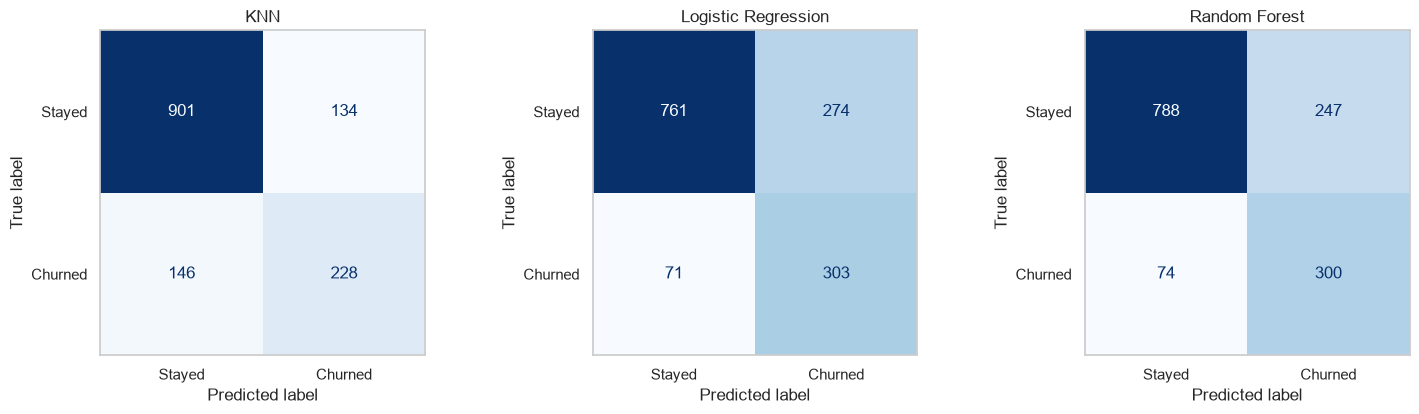

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, (model, X)) in zip(axes, final_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X, y_test, display_labels=["Stayed", "Churned"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
save_fig("M06_confusion_matrices", SAVE_FIGS)
plt.show()

In [20]:
# Generalisation check: CV F1 (training data) vs test F1
pd.DataFrame({
    "cv_f1": {name: s.best_score_ for name, s in searches.items()},
    "test_f1": test_results.loc[list(final_models), "f1"],
}).assign(difference=lambda t: t["test_f1"] - t["cv_f1"]).round(4)

,cv_f1,test_f1,difference
KNN,0.6000,0.6196,0.0196
Logistic Regression,0.6281,0.6372,0.0091
Random Forest,0.6317,0.6515,0.0198


## Predicting A New Customer

A new customer in the raw Kaggle format needs the **same cleaning** as in `02_preprocessing.ipynb`, then the **same fitted preprocessor** used for training (`preprocessor.transform`, never `fit_transform`), before the model can predict.

In [21]:
new_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.5, "TotalCharges": "171.0",
}])

# Same cleaning as the preprocessing notebook
new_customer["TotalCharges"] = pd.to_numeric(new_customer["TotalCharges"], errors="coerce").fillna(0)
new_customer["SeniorCitizen"] = new_customer["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Same fitted preprocessors as training
new_scaled = preprocessor_scaled.transform(new_customer)
new_rf = preprocessor_rf.transform(new_customer)

pd.DataFrame({
    "churn_probability": {
        "KNN": knn_search.best_estimator_.predict_proba(new_scaled)[0, 1],
        "Logistic Regression": lr_search.best_estimator_.predict_proba(new_scaled)[0, 1],
        "Random Forest": rf_search.best_estimator_.predict_proba(new_rf)[0, 1],
    }
}).assign(prediction=lambda t: np.where(t["churn_probability"] >= 0.5, "Churn", "Stay")).round(3)

,churn_probability,prediction
KNN,0.817,Churn
Logistic Regression,0.859,Churn
Random Forest,0.891,Churn


**Obstervation**

All three models predict churn with high probability (0.81 - 0.89) for this customer: 2 months' tenure, a month-to-month contract, fibre optic internet, electronic-check payment and no security or support add-ons. This matches the high-risk profile identified in the EDA.

### Results

| Model | Best hyperparameters | CV F1 | Test F1 | Test recall | Test precision | Test ROC-AUC | Test PR-AUC |
|---|---|---|---|---|---|---|---|
| **Random Forest** | 200 trees, no depth limit, min leaf 20, log2, balanced | **0.632** | **0.652** | 0.802 | 0.548 | **0.858** | **0.669** |
| Logistic Regression | C = 10, L2, balanced | 0.628 | 0.637 | **0.810** | 0.525 | 0.856 | 0.665 |
| K-Nearest Neighbours | k = 71, uniform, Manhattan | 0.600 | 0.620 | 0.610 | **0.630** | 0.850 | 0.641 |
| Baseline (majority class) | – | 0.000 | 0.000 | 0.000 | 0.000 | 0.500 | 0.265 |

### Key findings
1. **Accuracy is misleading.** The baseline scores 73.5% accuracy while catching no churners. Among the tuned models, KNN has the highest accuracy (0.801) but catches the fewest churners (228 of 374). F1, recall and AUC were used to compare models instead.
2. **Handling the class imbalance mattered most.** `class_weight="balanced"` raised recall by 0.26 for Logistic Regression and 0.28 for Random Forest, and improved F1 by 0.031 and 0.058, while ROC-AUC stayed almost unchanged. KNN cannot use class weights, so its recall stays much lower (0.61).
3. **Tuning improved every model and controlled overfitting.** Tuning raised CV F1 by +0.084 for Random Forest, +0.054 for KNN and +0.030 for Logistic Regression.
   - Random Forest needed a large minimum leaf size (20), which kept the training/CV gap to 0.028.
   - KNN needed a large k: its gap fell below 0.01 at k = 71, while `weights="distance"` overfit badly (gap of about 0.41).
   - Logistic Regression barely overfits at any setting (gap 0.001), and its CV F1 is almost flat for C between 0.1 and 100.
4. **The ranking is the same in CV and on the test set: Random Forest > Logistic Regression > KNN.** The gap between Random Forest and Logistic Regression is small, though: 0.004 in CV, well within the fold-to-fold variation (about 0.015), and 0.014 on the test set. KNN is clearly behind in both.
5. **The models make different kinds of errors.**
   - Random Forest catches **300 of the 374 churners** with 247 false alarms.
   - Logistic Regression catches **303** with 274 false alarms.
   - KNN catches only **228**, but raises the fewest false alarms (134).
6. **The models generalise well.** Test F1 is 0.009 - 0.020 *higher* than CV F1 for all three models, so none of them overfits the training data.

### Recommended model: Random Forest
- Best F1 in **cross-validation**, plus the best F1, ROC-AUC and PR-AUC on the **test set**, so the choice does not rest on the test set alone.
- Catches 80% of churners on unseen data, with fewer false alarms than Logistic Regression (247 vs 274) at almost the same recall.

**Logistic Regression is a strong alternative.** It is practically tied with Random Forest in cross-validation, overfits the least, and is simpler. Its coefficients show directly how each feature affects churn risk, so it is the better choice when explainability matters more than a small gain in performance. That is relevant to the transparency discussion in Task 3.

**KNN** has the lowest CV and test F1 and misses about 39% of churners. Without class weighting, it is the least suitable choice when catching churners is the priority.

### Limitations
- The difference between Random Forest and Logistic Regression is small relative to the CV variability, so another random split could reverse their ranking.
- All three models scored higher on the test set than in cross-validation, which suggests this particular test split is slightly easier. The CV scores are the more conservative estimate of real-world performance.
- All models use the default decision threshold of 0.5. A business could lower it to catch more churners (higher recall) or raise it to reduce false alarms (higher precision), depending on the cost of its retention actions.
- The data was encoded and scaled once before cross-validation, so the training-set means and standard deviations are shared across folds. A separate check during development showed this effect to be negligible (< 0.001 F1).
- The dataset is a single snapshot. In deployment, customer behaviour will change over time, so the model would need monitoring and periodic retraining.